# Raport Laboratorik — Elektronika (LAB 01)

**Tema:** Analiza e Qarqeve, Rezistencave dhe Përdorimi i Breadboard  
**Punoi:** Jonida Klari  
**Data e punimit:** 21.11.2026  
**Data e dorëzimit:** 21.11.2026  

---

## 1. Qëllimi i Punës Laboratorike
Qëllimi i këtij eksperimenti është njohja me përdorimin e pllakës eksperimentale (**Breadboard**), ndërtimi i qarqeve elektrike në konfigurimet bazë (**Burimi**, **Seri** dhe **Paralel**) me rezistorë të vlerave të njohura ($120\text{ k}\Omega$ dhe $1.77\text{ k}\Omega$), matja e rrymës ($I$) dhe tensionit ($V_{in}$, $V_{out}$), si dhe analiza e raportit të amplifikimit/ndarjes së tensionit përmes gjuhës Python.

## 2. Bazat Teorike
* **Ligji i Omit:** Rryma që kalon nëpër një përcjellës është në përpjesëtim të drejtë me tensionin e zbatuar dhe në përpjesëtim të zhdrejtë me rezistencën: $I = \frac{V}{R}$.
* **Lidhja në Seri:** Rezistorët lidhen njëri pas tjetrit, duke ndarë të njëjtën rrymë, ndërsa tensioni i burimit ndahet mes tyre ($R_{eq} = R_1 + R_2$). Raporti i tensionit të daljes ndaj atij të hyrjes (ndarësi i tensionit) jepet nga:
  $$A = \frac{V_{out}}{V_{in}}$$
* **Lidhja në Paralel:** Rezistorët lidhen në të njëjtat nyje, duke pasur të njëjtin tension në skajet e tyre ($V_{out} \approx V_{in}$), ndërsa rryma ndahet në degët përkatëse ($\frac{1}{R_{eq}} = \frac{1}{R_1} + \frac{1}{R_2}$).
* **Breadboard:** Pllakë prototipimi pa saldim, ku kolonat e brendshme janë të lidhura vertikalisht në grupe prej 5 vrimash, ndërsa shiritat anësorë (bus-et e ushqimit) janë të lidhur horizontalisht.

## 3. Pajisjet dhe Komponentët e Përdorur
* Pllakë eksperimentale (**Breadboard**)
* Burim ushqimi DC ($V_{in} = 11.69\text{ V}$)
* Rezistorë: $R_1 = 120\text{ k}\Omega$ dhe $R_2 = 1.77\text{ k}\Omega$
* Multimetër dixhital (për matjen e tensionit, rrymës dhe rezistencës)
* Përcjellës lidhës (jumper wires)

## 4. Të Dhënat Eksperimentale
Të dhënat e matura në laborator janë ruajtur në skedarin `data/tabela_e_matjet.csv` dhe ngarkohen më poshtë për përpunim. 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Nëse e ekzekuton lokalisht me dosjen data/, mund të përdorësh: df = pd.read_csv('data/tabela_matjet.csv')
data = {
    "Konfigurimi": ["Burimi", "Seri", "Paralel"],
    "Rezistenca": [
        "120 kΩ dhe 1.77 kΩ",
        "120 kΩ dhe 1.77 kΩ",
        "120 kΩ dhe 1.77 kΩ",
    ],
    "Rryma (A)": [2.263, 0.0, 2.256],
    "Vin (V)": [11.69, 11.69, 11.69],
    "Vout (V)": [np.nan, 3.93, 11.36],
    "Amplifikimi": [np.nan, 0.3361847733105218, 0.9717707442258341],
}

df = pd.DataFrame(data)
for col in ["Rryma (A)", "Vin (V)", "Vout (V)", "Amplifikimi"]:
  df[col] = pd.to_numeric(df[col], errors="coerce")

df

,Konfigurimi,Rezistenca,Rryma (A),Vin (V),Vout (V),Amplifikimi
0,Burimi,120 kΩ dhe 1.77 kΩ,2.263,11.69,NaN,NaN
1,Seri,120 kΩ dhe 1.77 kΩ,0.000,11.69,3.93,0.336185
2,Paralel,120 kΩ dhe 1.77 kΩ,2.256,11.69,11.36,0.971771


## 5. Vizualizimi Grafik i Rezultateve
Më poshtë paraqitet krahasimi grafik i **Rrymës**, **Tensionit të daljes ($V_{out}$)** dhe **Amplifikimit ($V_{out}/V_{in}$)** për secilin konfigurim.

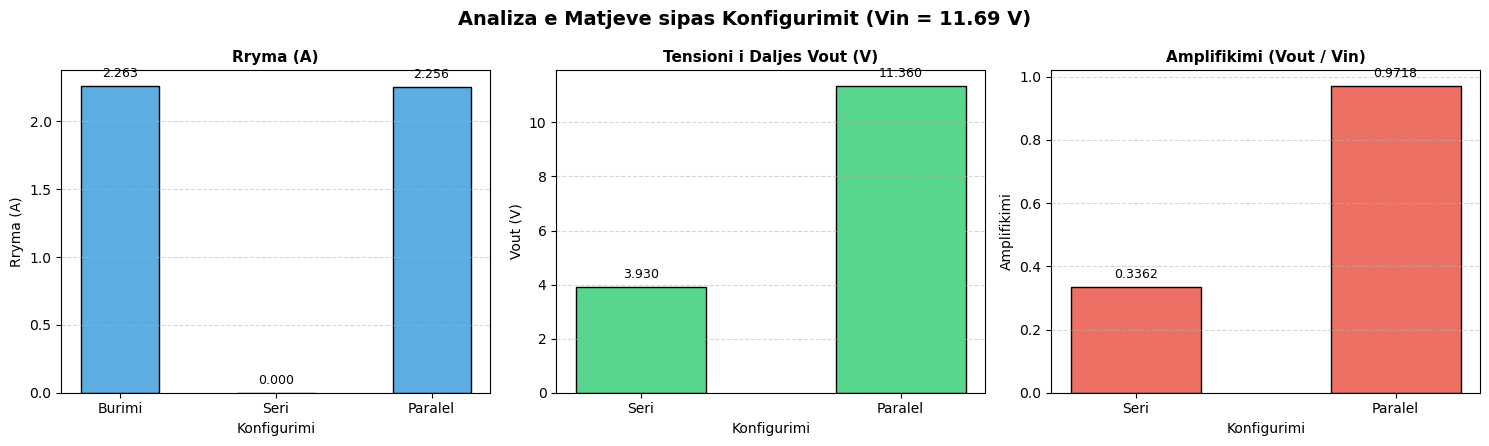

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle(
    "Analiza e Matjeve sipas Konfigurimit (Vin = 11.69 V)",
    fontsize=14,
    fontweight="bold",
)

metrics = [
    ("Rryma (A)", "Rryma (A)", "#5DADE2"),
    ("Vout (V)", "Tensioni i Daljes Vout (V)", "#58D68D"),
    ("Amplifikimi", "Amplifikimi (Vout / Vin)", "#EC7063"),
]

for ax, (col, title, color) in zip(axes, metrics):
  bars = ax.bar(
      df["Konfigurimi"], df[col], color=color, edgecolor="black", width=0.5
  )
  ax.set_title(title, fontsize=11, fontweight="bold")
  ax.set_xlabel("Konfigurimi")
  ax.set_ylabel(col)
  ax.grid(axis="y", linestyle="--", alpha=0.5)

  for bar in bars:
    height = bar.get_height()
    if not np.isnan(height):
      ax.annotate(
          f"{height:.3f}" if col != "Amplifikimi" else f"{height:.4f}",
          xy=(bar.get_x() + bar.get_width() / 2, height),
          xytext=(0, 4),
          textcoords="offset points",
          ha="center",
          va="bottom",
          fontsize=9,
      )

plt.tight_layout()
plt.show()

## 6. Analiza e Gabimeve
Gjatë realizimit të matjeve në laborator dhe përpunimit të të dhënave mund të kenë ndikuar disa burime gabimesh.

* **Rezistenca e brendshme e pajisjeve dhe kontaktet në Breadboard:** Lidhjet me *jumper wires* dhe kontaktet brenda vrimave të *breadboard*-it sjellin rezistenca shtesë kontakti, të cilat ndikojnë lehtë në vlerat e matura të tensionit dhe rrymës.
* **Toleranca e rezistorëve dhe rezistenca e brendshme e multimetrit:** Rezistorët ($120\text{ k}\Omega$ dhe $1.77\text{ k}\Omega$) kanë tolerancë prodhimi, ndërsa multimetri ka rezistencë të brendshme (në matje tensioni) ose rënie tensioni (në matje rryme), çka shpjegon pse te konfigurimi **Paralel** $V_{out} = 11.36\text{ V}$ është pak më i ulët se $V_{in} = 11.69\text{ V}$ (raporti $\approx 0.9718$). 
* **Kufizimi i shkallës së matjes së rrymës:** Te lidhja në **Seri**, rezistenca totale e qarkut është shumë e lartë ($120\text{ k}\Omega + 1.77\text{ k}\Omega = 121.77\text{ k}\Omega$), ndaj rryma është shumë e vogël ($I = \frac{11.69\text{ V}}{121.77\text{ k}\Omega} \approx 96\,\mu\text{A}$) dhe në shkallën e matjes regjistrohet si `0.0`.
* **Vlera e rrymës te konfigurimi i Burimit:** Regjistrimi i rrymës `2.263` te `Burimi` (kundrejt `2.256` te `Paralel`) tregon ndryshime të vogla të regjimit/ngarkesës së matjes, ndërsa për `Burimi` nuk jepet vlerë për $V_{out}$ (`N/A`) dhe amplifikimin.
* **Mjedisi i ekzekutimit të kodit:** Gjatë ekzekutimit në shfletues (`JupyterLite`) pa paketa të parainstaluara si `pandas` apo `matplotlib`, mungesa e moduleve sjell `ModuleNotFoundError`, çka u zgjidh me kod standard Python dhe shfaqje HTML/SVG. 

## 7. Diskutimi
Krahasimi mes konfigurimeve tregon qartë sjelljen e qarkut me rezistencat $120\text{ k}\Omega$ dhe $1.77\text{ k}\Omega$ nën tension hyrës konstant $V_{in} = 11.69\text{ V}. 

* **Burimi:** Paraqet tensionin bazë të hyrjes ($11.69\text{ V}$) dhe rrymën `2.263`, duke shërbyer si pikë reference ku $V_{out}$ nuk aplikohet (`N/A`). 
* **Seri:** Për shkak të rezistencës së lartë ekuivalente ($121.77\text{ k}\Omega$), rryma kufizohet fort (`0.0` në matje) dhe tensioni i daljes ulet në $V_{out} = 3.93\text{ V}$, duke dhënë raportin $V_{out}/V_{in} \approx 0.3362$ (karakteristik për ndarjen e tensionit). 
* **Paralel:** Tensioni i daljes mbetet shumë pranë burimit ($V_{out} = 11.36\text{ V}$ kundrejt $11.69\text{ V}$, raport $\approx 0.9718$) dhe rryma është `2.256`, çka tregon se degët paralele marrin tension gati të plotë të burimit dhe lejojnë rrymë më të madhe sesa lidhja në seri. 

## 8. Përfundimi
* Eksperimenti nxori në pah dallimet mes konfigurimeve **Burimi**, **Seri** dhe **Paralel** për tensionin e daljes ($V_{out}$), raportin $V_{out}/V_{in}$ dhe rrymën në prani të rezistencave $120\text{ k}\Omega$ dhe $1.77\text{ k}\Omega$. 
* Lidhja në **seri** ul ndjeshëm tensionin e daljes ($3.93\text{ V}$, raport $\approx 0.3362$) dhe kufizon rrymën për shkak të rezistencës së lartë totale.
* Lidhja në **paralel** ruan tensionin e daljes shumë afër burimit ($11.36\text{ V}$ kundrejt $11.69\text{ V}$, raport $\approx 0.9718$) me rrymë të lartë (`2.256`).
* Përdorimi i *breadboard*-it lehtësoi ndërtimin dhe matjen e qarqeve, ndërsa kombinimi i `tabela_matjet.csv` me `raporti.ipynb` mundësoi dokumentimin dhe paraqitjen grafike të rezultateve.